# 02 – Validation against Copernicus EMS (EMSR692)

The Sentinel-1 flood map of notebook 01 is compared with the official **Copernicus Emergency Management Service** rapid-mapping products for Storm Daniel (activation **EMSR692**), produced by analysts from very-high-resolution imagery.

* Reference: EMS products closest to 12–13 September 2023 for AOIs 02 Palamas, 03 Larissa, 04 Stefanovikio and 05 Karditsa
* EMS distinguishes **"Flooded area"** (standing water) and **"Flood trace"** (water already receded, traces remain). Only *Flooded area* is used as the flood reference.
* Metrics are computed **only inside the EMS areas of interest**, where a reference exists.

Workflow: our flood map is downloaded from Earth Engine as a GeoTIFF (30 m, Greek Grid), the EMS polygons are rasterised on the same grid with `rasterio`, and the comparison is done locally with NumPy.

In [1]:
import sys, glob
from pathlib import Path
import ee, geemap
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.features import rasterize
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from pathlib import Path
# Your Earth Engine project id lives in project_id.txt (project root, not uploaded to GitHub)
_pid_file = Path.cwd().parent / "project_id.txt"
PROJECT_ID = _pid_file.read_text().strip() if _pid_file.exists() else "your-gcp-project-id"
ee.Initialize(project=PROJECT_ID)

ROOT = Path.cwd().parent            # project root (this notebook lives in notebooks/)
sys.path.append(str(ROOT))
from src.flood import get_aoi, peak_flood

aoi = get_aoi()
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

## 1. Load the EMS reference

Unzip the EMS vector packages into `data/ems/` (one folder per product).

In [2]:
EMS_DIR = ROOT / "data" / "ems"

# Products closest to 12–13 September 2023
REF_PRODUCTS = ["AOI02_DEL_MONIT01", "AOI03_DEL_MONIT01", "AOI04_DEL_MONIT01", "AOI05_DEL_MONIT02"]

def read_layer(product, layer):
    path = glob.glob(str(EMS_DIR / f"EMSR692_{product}*" / f"*{layer}A*.shp"))[0]
    return gpd.read_file(path).assign(product=product)

events = pd.concat([read_layer(p, "observedEvent") for p in REF_PRODUCTS], ignore_index=True).to_crs(2100)
ems_aois = pd.concat([read_layer(p, "areaOfInterest") for p in REF_PRODUCTS], ignore_index=True).to_crs(2100)

summary = (events.assign(km2=events.area / 1e6)
           .pivot_table(index="product", columns="notation", values="km2", aggfunc="sum")
           .round(1))
summary.loc["Total"] = summary.sum()
summary

notation,Flood trace,Flooded area
product,,
AOI02_DEL_MONIT01,485.1,113.0
AOI03_DEL_MONIT01,30.8,126.3
AOI04_DEL_MONIT01,13.3,140.1
AOI05_DEL_MONIT02,232.9,96.9
Total,762.1,476.3


## 2. Download our flood map

Values: **1** flooded · **0** not flooded · **255** no Sentinel-1 data.

In [3]:
def download_flood(path, scale=30, **params):
    flood, covered = peak_flood(aoi, **params)
    img = flood.unmask(0).where(covered.unmask(0).eq(0), 255).toByte()
    geemap.ee_export_image(img, filename=str(path), scale=scale, crs="EPSG:2100",
                           region=aoi, verbose=False)
    return path

flood_tif = download_flood(OUT / "flood_peak_30m.tif")

with rasterio.open(flood_tif) as src:
    ours = src.read(1)
    transform, shape = src.transform, src.shape
print("Raster size:", shape, "| pixel:", transform.a, "m")
print(f"Flooded area in our map: {(ours == 1).sum() * transform.a ** 2 / 1e6:.1f} km²")

Raster size: (2478, 3772) | pixel: 30.0 m
Flooded area in our map: 330.5 km²


## 3. Rasterise the EMS reference on the same grid

In [4]:
def burn(gdf):
    return rasterize(((g, 1) for g in gdf.geometry if g is not None and not g.is_empty),
                     out_shape=shape, transform=transform, fill=0, dtype="uint8")

ref_flooded = burn(events[events.notation == "Flooded area"]).astype(bool)
ref_trace = burn(events[events.notation == "Flood trace"]).astype(bool)
inside_ems = burn(ems_aois).astype(bool)

px_km2 = transform.a ** 2 / 1e6
print(f"EMS flooded area on the grid: {ref_flooded.sum() * px_km2:.1f} km²")

EMS flooded area on the grid: 455.1 km²


## 4. Agreement metrics

* **TP** – flooded in both maps · **FP** – flooded only in ours · **FN** – flooded only in EMS
* **Precision** = TP / (TP + FP): how much of what we mapped is correct
* **Recall** = TP / (TP + FN): how much of the real flood we found
* **F1** – harmonic mean of precision and recall · **IoU** = TP / (TP + FP + FN)

In [5]:
def metrics(pred, ref, valid):
    p, r = pred[valid], ref[valid]
    tp, fp, fn = (p & r).sum(), (p & ~r).sum(), (~p & r).sum()
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"TP_km2": tp * px_km2, "FP_km2": fp * px_km2, "FN_km2": fn * px_km2,
            "precision": precision, "recall": recall, "F1": f1, "IoU": tp / (tp + fp + fn)}

pred = ours == 1
valid = inside_ems & (ours != 255)

results = pd.DataFrame({
    "All EMS area": metrics(pred, ref_flooded, valid),
    "Without flood traces": metrics(pred, ref_flooded, valid & ~ref_trace),
}).T.round(3)
results

,TP_km2,FP_km2,FN_km2,precision,recall,F1,IoU
All EMS area,294.244,26.808,159.156,0.916,0.649,0.760,0.613
Without flood traces,294.242,14.513,159.142,0.953,0.649,0.772,0.629


In [6]:
# How much of what we call "false positive" is actually an EMS flood trace?
fp_on_trace = (pred & ~ref_flooded & ref_trace & valid).sum() * px_km2
fp_total = (pred & ~ref_flooded & valid).sum() * px_km2
print(f"False positives: {fp_total:.1f} km², of which on EMS flood traces: {fp_on_trace:.1f} km² "
      f"({fp_on_trace / fp_total:.0%})")

False positives: 26.8 km², of which on EMS flood traces: 12.3 km² (46%)


## 5. Map of agreement

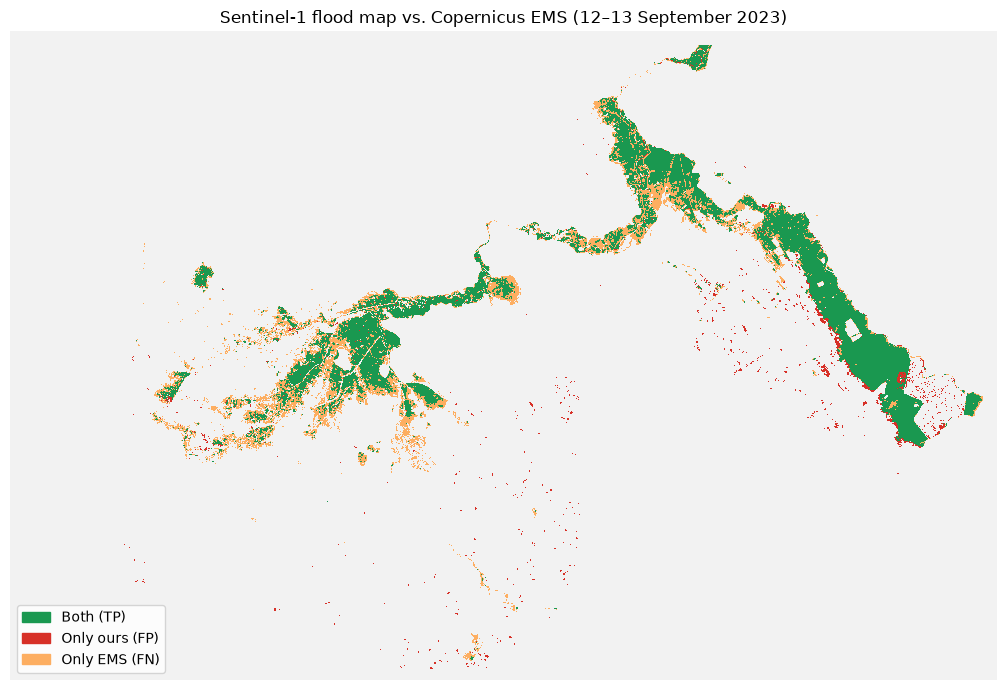

In [7]:
agree = np.zeros(shape, dtype="uint8")
agree[pred & ref_flooded] = 1                 # TP
agree[pred & ~ref_flooded] = 2                # FP
agree[~pred & ref_flooded] = 3                # FN
agree[~inside_ems | (ours == 255)] = 0

cmap = ListedColormap(["#f2f2f2", "#1a9850", "#d73027", "#fdae61"])
fig, ax = plt.subplots(figsize=(11, 7))
ax.imshow(agree, cmap=cmap, vmin=0, vmax=3, interpolation="nearest")
ax.set_axis_off()
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in cmap.colors[1:]]
ax.legend(handles, ["Both (TP)", "Only ours (FP)", "Only EMS (FN)"], loc="lower left")
ax.set_title("Sentinel-1 flood map vs. Copernicus EMS (12–13 September 2023)")
plt.tight_layout()
plt.savefig(OUT / "agreement_map.png", dpi=150)
plt.show()

## 6. Sensitivity to the thresholds

Which combination of thresholds agrees best with EMS? Each run downloads a new map (a few minutes in total).

In [8]:
import time

def download_checked(path, tries=3, **params):
    """geemap can fail silently (verbose=False): check that the file exists, retry if not."""
    for attempt in range(1, tries + 1):
        if path.exists() and path.stat().st_size > 0:
            return path
        try:
            download_flood(path, **params)
        except Exception as e:
            print(f"  attempt {attempt} failed: {e}")
        time.sleep(3)
    if path.exists() and path.stat().st_size > 0:
        return path
    raise FileNotFoundError(f"Could not download {path.name} after {tries} tries")

rows = []
for diff_thr in [-2, -3, -4]:
    for post_thr in [-14, -16, -18]:
        path = download_checked(OUT / f"sens_{abs(diff_thr)}_{abs(post_thr)}.tif",
                                diff_thr=diff_thr, post_thr=post_thr)
        with rasterio.open(path) as src:
            arr = src.read(1)
        res = metrics(arr == 1, ref_flooded, inside_ems & (arr != 255) & ~ref_trace)
        rows.append({"diff_thr": diff_thr, "post_thr": post_thr, **res})
        print(f"diff {diff_thr:>3} dB, post {post_thr:>4} dB  ->  F1 = {res['F1']:.3f}")

sens = pd.DataFrame(rows)
f1_table = sens.pivot(index="diff_thr", columns="post_thr", values="F1").round(3)
f1_table

diff  -2 dB, post  -14 dB  ->  F1 = 0.779
diff  -2 dB, post  -16 dB  ->  F1 = 0.760
diff  -2 dB, post  -18 dB  ->  F1 = 0.726
diff  -3 dB, post  -14 dB  ->  F1 = 0.779
diff  -3 dB, post  -16 dB  ->  F1 = 0.762
diff  -3 dB, post  -18 dB  ->  F1 = 0.728
diff  -4 dB, post  -14 dB  ->  F1 = 0.770
diff  -4 dB, post  -16 dB  ->  F1 = 0.756
diff  -4 dB, post  -18 dB  ->  F1 = 0.727


post_thr,-18,-16,-14
diff_thr,,,
-4,0.727,0.756,0.770
-3,0.728,0.762,0.779
-2,0.726,0.760,0.779


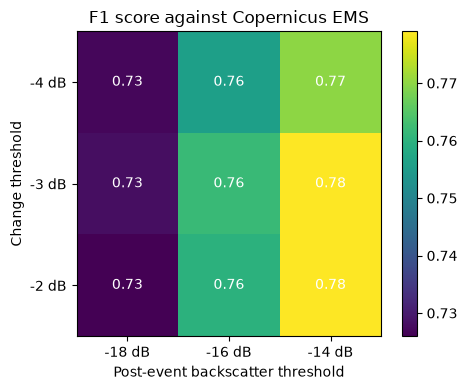

In [9]:
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(f1_table.values, cmap="viridis")
ax.set_xticks(range(len(f1_table.columns)), [f"{c} dB" for c in f1_table.columns])
ax.set_yticks(range(len(f1_table.index)), [f"{i} dB" for i in f1_table.index])
ax.set_xlabel("Post-event backscatter threshold")
ax.set_ylabel("Change threshold")
for i in range(f1_table.shape[0]):
    for j in range(f1_table.shape[1]):
        ax.text(j, i, f"{f1_table.values[i, j]:.2f}", ha="center", va="center", color="white")
ax.set_title("F1 score against Copernicus EMS")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(OUT / "threshold_sensitivity.png", dpi=150)
plt.show()

## 7. Robustness against EMS: other choices in the method

Section 6 changed the two thresholds. Here we change **one choice at a time** (speckle filter, minimum cluster size, slope limit, length of the "before" window) and see how well each variant agrees with EMS.
The list of variants is `SCENARIOS` in `src/flood.py`. If the score hardly moves, the result does not depend on that choice.
Each run downloads a map, so this takes a while (the files are cached in `outputs/`).

In [10]:
import hashlib, json
from src.flood import SCENARIOS

rows = []
for label, params in SCENARIOS.items():
    tag = hashlib.md5(json.dumps(params, sort_keys=True).encode()).hexdigest()[:8]
    path = download_checked(OUT / f"rob_{tag}.tif", **params)
    with rasterio.open(path) as src:
        arr = src.read(1)
    if arr.shape != shape:
        print(f"skipped {label}: raster shape {arr.shape} differs from {shape}")
        continue
    res = metrics(arr == 1, ref_flooded, inside_ems & (arr != 255) & ~ref_trace)
    rows.append({"scenario": label, "flooded_km2": (arr == 1).sum() * px_km2, **res})
    print(f"{label:<28} F1 = {res['F1']:.3f}  precision = {res['precision']:.3f}  recall = {res['recall']:.3f}")

rob = pd.DataFrame(rows).set_index("scenario")
rob.to_csv(OUT / "ems_robustness.csv")
rob[["flooded_km2", "precision", "recall", "F1", "IoU"]].round(3)

baseline                     F1 = 0.772  precision = 0.953  recall = 0.649
change < -2 dB               F1 = 0.772  precision = 0.928  recall = 0.661
change < -4 dB               F1 = 0.764  precision = 0.968  recall = 0.632
post < -13 dB                F1 = 0.784  precision = 0.940  recall = 0.673
post < -17 dB                F1 = 0.747  precision = 0.966  recall = 0.609
speckle filter 30 m          F1 = 0.771  precision = 0.947  recall = 0.650
speckle filter 80 m          F1 = 0.774  precision = 0.961  recall = 0.648
min cluster 4 px             F1 = 0.772  precision = 0.946  recall = 0.652
min cluster 16 px            F1 = 0.771  precision = 0.960  recall = 0.644
max slope 3°                 F1 = 0.720  precision = 0.955  recall = 0.578
max slope 10°                F1 = 0.776  precision = 0.950  recall = 0.655
before-window from 1 Aug     F1 = 0.770  precision = 0.945  recall = 0.650
before-window from 1 Jul     F1 = 0.769  precision = 0.936  recall = 0.652
before-window 25 Aug–4 Se

,flooded_km2,precision,recall,F1,IoU
scenario,,,,,
baseline,330.505,0.953,0.649,0.772,0.629
change < -2 dB,355.388,0.928,0.661,0.772,0.628
change < -4 dB,310.587,0.968,0.632,0.764,0.619
post < -13 dB,354.230,0.940,0.673,0.784,0.645
post < -17 dB,296.402,0.966,0.609,0.747,0.596
speckle filter 30 m,334.852,0.947,0.650,0.771,0.627
speckle filter 80 m,324.219,0.961,0.648,0.774,0.631
min cluster 4 px,337.195,0.946,0.652,0.772,0.628
min cluster 16 px,322.386,0.960,0.644,0.771,0.627


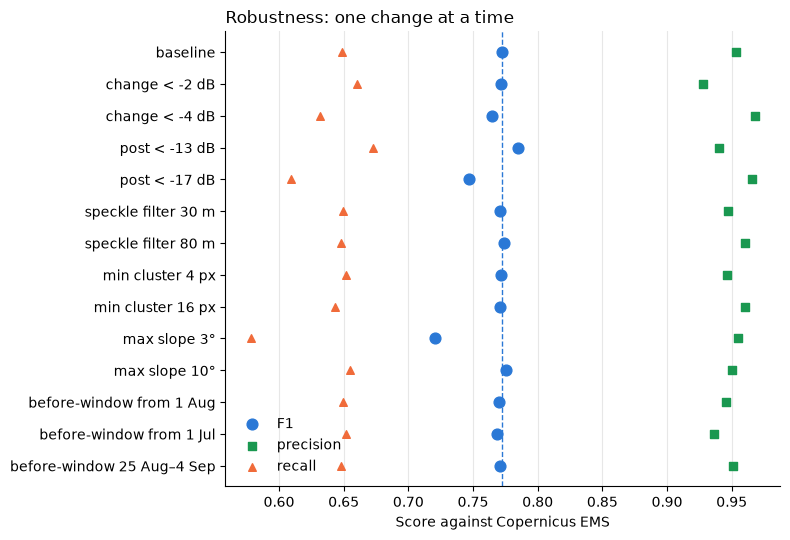

In [11]:
fig, ax = plt.subplots(figsize=(8, 5.5))
y = np.arange(len(rob))
ax.scatter(rob["F1"], y, s=60, color="#2a78d6", label="F1", zorder=3)
ax.scatter(rob["precision"], y, s=30, marker="s", color="#1a9850", label="precision", zorder=3)
ax.scatter(rob["recall"], y, s=30, marker="^", color="#f06b3a", label="recall", zorder=3)
ax.axvline(rob.loc["baseline", "F1"], color="#2a78d6", ls="--", lw=1)
ax.set_yticks(y, rob.index); ax.invert_yaxis()
ax.set_xlabel("Score against Copernicus EMS")
ax.set_title("Robustness: one change at a time", loc="left")
ax.grid(axis="x", alpha=0.3); ax.legend(frameon=False, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUT / "ems_robustness.png", dpi=150)
plt.show()

## 8. Does the score depend on where we look?

The metrics so far pool four EMS areas. If one area is much worse than the others, the pooled score hides it. (EMS areas can overlap, so the numbers are not additive.)

In [12]:
rows = []
for prod in REF_PRODUCTS:
    inside_p = burn(ems_aois[ems_aois["product"] == prod]).astype(bool)
    v = inside_p & (ours != 255) & ~ref_trace
    if v.sum() == 0:
        continue
    rows.append({"EMS area": prod, "EMS flooded km2": (ref_flooded & v).sum() * px_km2,
                 **metrics(pred, ref_flooded, v)})
pd.DataFrame(rows).set_index("EMS area")[["EMS flooded km2", "precision", "recall", "F1", "IoU"]].round(3)

,EMS flooded km2,precision,recall,F1,IoU
EMS area,,,,,
AOI02_DEL_MONIT01,113.061,0.977,0.613,0.753,0.604
AOI03_DEL_MONIT01,125.392,0.944,0.610,0.741,0.589
AOI04_DEL_MONIT01,118.702,0.937,0.926,0.932,0.872
AOI05_DEL_MONIT02,97.074,0.975,0.402,0.569,0.398


## 9. How uncertain is the score? (block bootstrap)

Neighbouring pixels are not independent, so we resample **blocks** of 50 × 50 pixels (1.5 km) instead of single pixels, 1000 times, and report the 95% range of each score.
This shows how much the score depends on which parts of the EMS area we happen to have. It does **not** include errors of the EMS map itself.

In [13]:
def block_bootstrap(pred, ref, valid, block=50, n=1000, seed=0):
    rows_, cols_ = np.indices(pred.shape)
    ids = (rows_ // block) * (pred.shape[1] // block + 1) + (cols_ // block)
    k = ids.max() + 1
    def count(mask):
        return np.bincount(ids[valid & mask], minlength=k).astype(float)
    tp, fp, fn = count(pred & ref), count(pred & ~ref), count(~pred & ref)
    keep = np.flatnonzero(tp + fp + fn > 0)
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(n):
        s = rng.choice(keep, size=len(keep), replace=True)
        t, f_p, f_n = tp[s].sum(), fp[s].sum(), fn[s].sum()
        p, r = t / (t + f_p), t / (t + f_n)
        out.append((p, r, 2 * p * r / (p + r)))
    return np.percentile(np.array(out), [2.5, 50, 97.5], axis=0)

v = inside_ems & (ours != 255) & ~ref_trace
q = block_bootstrap(pred, ref_flooded, v)
point = metrics(pred, ref_flooded, v)
pd.DataFrame({"estimate": [point["precision"], point["recall"], point["F1"]],
              "2.5%": q[0], "median": q[1], "97.5%": q[2]},
             index=["precision", "recall", "F1"]).round(3)

,estimate,2.5%,median,97.5%
precision,0.953,0.943,0.953,0.962
recall,0.649,0.619,0.648,0.678
F1,0.772,0.750,0.771,0.794


## 10. Timing: when was the EMS image taken, and when did Sentinel-1 pass?

The EMS maps are made from satellite images taken at a specific moment, and the water level was changing quickly at that time. The `source` table of each EMS product says which image was used.

In [14]:
src_tables = []
for p in REF_PRODUCTS:
    folder = next(EMS_DIR.glob(f"EMSR692_{p}*"))
    t = gpd.read_file(next(folder.glob("*_source_*.dbf")))
    t["product"] = p
    src_tables.append(t)
src_tables = pd.concat(src_tables, ignore_index=True)
src_tables["src_id"] = src_tables["src_id"].astype(str)

# The image that the "observedEvent" polygons were drawn from (dmg_src_id -> src_id)
used = events[["product", "dmg_src_id"]].drop_duplicates().astype({"dmg_src_id": str})
used.merge(src_tables, left_on=["product", "dmg_src_id"], right_on=["product", "src_id"], how="left")[
    ["product", "source_nam", "src_date", "source_tm", "sensor_res"]]

,product,source_nam,src_date,source_tm,sensor_res
0,AOI02_DEL_MONIT01,SPOT-6-7,12/09/2023,T08:54:06Z,1.5 m
1,AOI03_DEL_MONIT01,SPOT-6-7,12/09/2023,T08:53:48Z,1.5 m
2,AOI04_DEL_MONIT01,SPOT-6-7,12/09/2023,T08:53:48Z,1.5 m
3,AOI05_DEL_MONIT02,SPOT-6-7,12/09/2023,T08:54:00Z,1.5 m


Sentinel-1 times (UTC, from the table in notebook 01): orbit 175 on 12 Sep at **16:32**, orbit 7 on 13 Sep at **04:31**.
The reference images are from the morning of 12 Sep (about 08:54 UTC), so the radar passes are 7.6 h and 19.6 h later.
The second EMS date of each area (14 Sep, about 08:38–09:16 UTC) lets us test a second moment.

The next cell scores each Sentinel-1 map (the 12 Sep pass, the 13 Sep pass, and their union) against each EMS date. Compare the recall across rows:
if it is clearly higher for the pass closest in time to the EMS image, part of the water we "miss" had already moved or receded by the time of the radar pass.

*Update:* an EMS image may cover only part of the area of interest. Pixels of the area that the image does not cover would wrongly count as "not flooded" in the reference, and lower the precision.
The cell above therefore only scores pixels inside the footprint of the post-event EMS image, and reports how much of the area that is.

In [15]:
REF_12 = REF_PRODUCTS
REF_14 = ["AOI02_DEL_MONIT02", "AOI03_DEL_MONIT02", "AOI04_DEL_MONIT02", "AOI05_DEL_MONIT03"]

def download_img(path, img, tries=3):
    for attempt in range(1, tries + 1):
        if path.exists() and path.stat().st_size > 0:
            return path
        try:
            geemap.ee_export_image(img, filename=str(path), scale=30, crs="EPSG:2100", region=aoi, verbose=False)
        except Exception as e:
            print(f"  attempt {attempt} failed: {e}")
        time.sleep(3)
    if path.exists() and path.stat().st_size > 0:
        return path
    raise FileNotFoundError(f"Could not download {path.name}")

from src.flood import flood_map
arrays = {"union of both passes": ours}
for label, (d0, d1) in {"12 Sep 16:32 (orbit 175)": ("2023-09-12", "2023-09-13"),
                        "13 Sep 04:31 (orbit 7)": ("2023-09-13", "2023-09-14")}.items():
    flood, covered = flood_map(aoi, d0, d1)
    img = flood.unmask(0).where(covered.unmask(0).eq(0), 255).toByte()
    path = download_img(OUT / f"pass_{d0}.tif", img)
    with rasterio.open(path) as s:
        arrays[label] = s.read(1)

def ref_mask(product, ev_p):
    """Where the EMS reference exists: inside the area of interest AND inside the footprint of the post-event image."""
    aoi_m = burn(read_layer(product, "areaOfInterest").to_crs(2100)).astype(bool)
    fp = read_layer(product, "imageFootprint").to_crs(2100)
    fp = fp[fp["or_src_id"].astype(str).isin(set(ev_p["dmg_src_id"].astype(str)))]
    if len(fp) == 0:
        print(f"  {product}: no matching image footprint, using the whole area of interest")
        return aoi_m
    return aoi_m & burn(fp).astype(bool)

def evaluate(products, arr, ref_label, s1_label):
    ev = pd.concat([read_layer(p, "observedEvent") for p in products], ignore_index=True).to_crs(2100)
    flooded = burn(ev[ev.notation == "Flooded area"]).astype(bool)
    trace = burn(ev[ev.notation == "Flood trace"]).astype(bool)
    out = []
    for p in products:
        ev_p = ev[ev["product"] == p]
        inside = ref_mask(p, ev_p)
        aoi_px = burn(read_layer(p, "areaOfInterest").to_crs(2100)).sum()
        v = inside & (arr != 255) & ~trace          # only where the EMS image AND this pass have data
        if v.sum() == 0:
            continue
        out.append({"EMS image": ref_label, "Sentinel-1": s1_label, "area": p[:5],
                    "EMS image covers % of area": 100 * inside.sum() / aoi_px,
                    "EMS flooded km² seen": (flooded & v).sum() * px_km2,
                    **metrics(arr == 1, flooded, v)})
    return out

rows = []
for ref_label, prods in [("12 Sep 08:54", REF_12), ("14 Sep 08:38-09:16", REF_14)]:
    for s1_label, arr in arrays.items():
        rows += evaluate(prods, arr, ref_label, s1_label)

timing = pd.DataFrame(rows).set_index(["EMS image", "Sentinel-1", "area"])
timing.to_csv(OUT / "ems_timing.csv")
timing[["EMS image covers % of area", "EMS flooded km² seen", "precision", "recall", "F1"]].round(2)

EMS image covers % of area  \
EMS image          Sentinel-1               area                                
12 Sep 08:54       union of both passes     AOI02                      100.00   
                                            AOI03                      100.00   
                                            AOI04                      100.00   
                                            AOI05                       99.99   
                   12 Sep 16:32 (orbit 175) AOI02                      100.00   
                                            AOI03                      100.00   
                                            AOI04                      100.00   
                                            AOI05                       99.99   
                   13 Sep 04:31 (orbit 7)   AOI02                      100.00   
                                            AOI03                      100.00   
                                            AOI04                      100.00   
                                            AOI05                       99.99   
14 Sep 08:38-09:16 union of both passes     AOI02                      100.00   
                                            AOI03                      100.00   
                                            AOI04                      100.00   
                                            AOI05                      100.00   
                   12 Sep 16:32 (orbit 175) AOI02                      100.00   
                                            AOI03                      100.00   
                                            AOI04                      100.00   
                                            AOI05                      100.00   
                   13 Sep 04:31 (orbit 7)   AOI02                      100.00   
                                            AOI03                      100.00   
                                            AOI04                      100.00   
                                            AOI05                      100.00   

                                                   EMS flooded km² seen  \
EMS image          Sentinel-1               area                          
12 Sep 08:54       union of both passes     AOI02                113.06   
                                            AOI03                125.39   
                                            AOI04                118.70   
                                            AOI05                 97.07   
                   12 Sep 16:32 (orbit 175) AOI02                113.06   
                                            AOI03                126.44   
                                            AOI04                 33.51   
                                            AOI05                 97.07   
                   13 Sep 04:31 (orbit 7)   AOI02                113.06   
                                            AOI03                126.44   
                                            AOI04                119.31   
                                            AOI05                 82.78   
14 Sep 08:38-09:16 union of both passes     AOI02                 60.46   
                                            AOI03                 90.64   
                                            AOI04                118.94   
                                            AOI05                 80.83   
                   12 Sep 16:32 (orbit 175) AOI02                 60.46   
                                            AOI03                 91.61   
                                            AOI04                 30.99   
                                            AOI05                 80.83   
                   13 Sep 04:31 (orbit 7)   AOI02                 60.46   
                                            AOI03                 91.61   
                                            AOI04                119.42   
                                            AOI05                 68.

**How to read it.** Rows where *EMS flooded km² seen* is small have little data from that pass in that area, so ignore them.
This test shows whether timing matters. It does not say which pass is "right": the EMS map is itself an interpretation of one image.

## 11. Which land cover do we miss? (recall by land cover)

The headline number of this project is flooded **cropland**, so what matters is how well we detect water on cropland specifically.
We compare the 12 Sep EMS references with our union map, split by ESA WorldCover class (resampled to the 30 m grid by nearest neighbour).

In [16]:
from IPython.display import display

lc_img = ee.ImageCollection("ESA/WorldCover/v200").first().select("Map").toByte()
lc_path = download_img(OUT / "worldcover_30m.tif", lc_img)
with rasterio.open(lc_path) as s:
    lc = s.read(1)
assert lc.shape == shape

classes = {
    "cropland": lc == 40,
    "built-up": lc == 50,
    "tree cover": lc == 10,
    "grass / shrub": np.isin(lc, [20, 30]),
    "other": ~np.isin(lc, [10, 20, 30, 40, 50]),
}

mask12 = np.zeros(shape, bool)
for p in REF_PRODUCTS:
    mask12 |= ref_mask(p, events[events["product"] == p])
valid12 = mask12 & (ours != 255) & ~ref_trace

rows = [{"land cover": name, "EMS flooded km²": (ref_flooded & valid12 & m).sum() * px_km2,
         **metrics(pred, ref_flooded, valid12 & m)} for name, m in classes.items()
        if (ref_flooded & valid12 & m).sum() > 0]
by_class = pd.DataFrame(rows).set_index("land cover")[["EMS flooded km²", "precision", "recall", "F1"]].round(2)

rows = []
for p in REF_PRODUCTS:
    mp = ref_mask(p, events[events["product"] == p]) & (ours != 255) & ~ref_trace
    for name, m in [("cropland", lc == 40), ("not cropland", lc != 40)]:
        v = mp & m
        if (ref_flooded & v).sum() == 0:
            continue
        rows.append({"area": p[:5], "land cover": name, "EMS flooded km²": (ref_flooded & v).sum() * px_km2,
                     **metrics(pred, ref_flooded, v)})
by_aoi = pd.DataFrame(rows).set_index(["area", "land cover"])[["EMS flooded km²", "precision", "recall", "F1"]].round(2)

by_class.to_csv(OUT / "ems_recall_by_landcover.csv")
display(by_class); display(by_aoi)

,EMS flooded km²,precision,recall,F1
land cover,,,,
cropland,387.40,0.97,0.69,0.81
built-up,6.69,0.95,0.19,0.31
tree cover,20.23,0.91,0.22,0.36
grass / shrub,36.48,0.97,0.56,0.71
other,2.60,0.18,0.48,0.26


EMS flooded km²  precision  recall    F1
area  land cover                                            
AOI02 cropland               101.04       0.98    0.64  0.77
      not cropland            12.02       0.98    0.38  0.55
AOI03 cropland                93.98       0.96    0.70  0.81
      not cropland            31.41       0.88    0.34  0.49
AOI04 cropland               103.52       0.98    0.96  0.97
      not cropland            15.18       0.68    0.70  0.69
AOI05 cropland                89.46       0.98    0.42  0.58
      not cropland             7.62       0.88    0.23  0.37

**How to read it.** If recall is clearly lower on cropland than on other classes, the flooded-cropland figure is a lower bound by roughly that factor.
Precision by class is less reliable than recall, because EMS only maps what its analysts could see.

## 12. Do we miss the shallow water? (recall by EMS water depth)

Each EMS product also has a `waterDepth` layer. It is usually an estimate computed from the flood extent and a terrain model, not a measurement (check the product's metadata), but it still tells us whether the water we miss is mostly shallow.
We split the EMS flooded cropland pixels into four groups of equal size by depth and look at the recall in each.

In [17]:
import re

gdfs = {}
for p in REF_PRODUCTS:
    shp = glob.glob(str(EMS_DIR / f"EMSR692_{p}*" / "*waterDepthA*.shp"))
    if not shp:
        print(f"{p}: no waterDepth layer")
        continue
    g = gpd.read_file(shp[0]).to_crs(2100)
    gdfs[p] = g
    print(f"{p}: {len(g)} polygons | 'value' type: {g['value'].dtype} | examples: {list(g['value'].astype(str).unique()[:6])}")

all_vals = pd.concat([g["value"] for g in gdfs.values()]).dropna()
as_number = pd.to_numeric(all_vals, errors="coerce").notna().all() and all_vals.nunique() > 8
print("\nTreating depth as:", "a number (4 groups of equal size)" if as_number else "classes (one group per class)")

def first_number(text):
    m = re.search(r"-?\d+(?:[.,]\d+)?", str(text))
    return float(m.group().replace(",", ".")) if m else float("inf")

if as_number:
    labels = None
    depth = np.full(shape, np.nan, dtype="float32")
    for p, g in gdfs.items():
        g = g.assign(value=pd.to_numeric(g["value"], errors="coerce")).dropna(subset=["value"])
        d = rasterize(((geom, val) for geom, val in zip(g.geometry, g["value"]) if geom is not None and not geom.is_empty),
                      out_shape=shape, transform=transform, fill=np.nan, dtype="float32")
        depth = np.where(np.isnan(depth), d, depth)
    has_depth = ~np.isnan(depth)
else:
    labels = sorted({str(v) for v in all_vals}, key=first_number)
    code_of = {lab: i + 1 for i, lab in enumerate(labels)}
    depth_code = np.zeros(shape, dtype="int16")
    for p, g in gdfs.items():
        d = rasterize(((geom, code_of[str(val)]) for geom, val in zip(g.geometry, g["value"])
                       if geom is not None and not geom.is_empty and pd.notna(val)),
                      out_shape=shape, transform=transform, fill=0, dtype="int16")
        depth_code = np.where(depth_code == 0, d, depth_code)
    has_depth = depth_code > 0

crop = classes["cropland"]
pix = valid12 & ref_flooded & crop
print(f"\nEMS flooded cropland pixels that have a depth value: {(pix & has_depth).sum() / pix.sum():.0%}")

AOI02_DEL_MONIT01: 15074 polygons | 'value' type: str | examples: ['0.50 - 1.00', '2.00 - 4.00', '1.00 - 2.00', '4.00 - 6.00', '0.15 - 0.50']
AOI03_DEL_MONIT01: 1745 polygons | 'value' type: str | examples: ['0.50 - 1.00', '0.15 - 0.50', '1.00 - 2.00', '2.00 - 4.00', '4.00 - 6.00']
AOI04_DEL_MONIT01: 1343 polygons | 'value' type: str | examples: ['1.00 - 2.00', '0.50 - 1.00', '2.00 - 4.00', '0.15 - 0.50', '4.00 - 6.00']
AOI05_DEL_MONIT02: 1129 polygons | 'value' type: str | examples: ['0.15 - 0.50', '0.50 - 1.00', '1.00 - 2.00', '2.00 - 4.00']

Treating depth as: classes (one group per class)

EMS flooded cropland pixels that have a depth value: 100%


In [18]:
known = pix & has_depth
if known.sum() == 0:
    print("The depth polygons do not overlap the flooded polygons, so there is nothing to compare. "
          "Send the printed examples above; the waterDepth .tif in each product may be the better source.")
else:
    group = np.full(shape, "", dtype=object)
    if as_number:
        group[known] = pd.qcut(depth[known], 4, duplicates="drop").astype(str)
    else:
        group[known] = np.array(labels, dtype=object)[depth_code[known] - 1]

    def by_group(mask):
        t = (pd.DataFrame({"depth": group[mask], "detected": pred[mask]})
               .groupby("depth")["detected"].agg(recall="mean", pixels="size"))
        t["EMS flooded km²"] = t["pixels"] * px_km2
        return t.sort_index(key=lambda idx: [first_number(x) for x in idx])

    display(by_group(known)[["EMS flooded km²", "recall"]].round(2))

    cols = {}
    for p in REF_PRODUCTS:
        mp = known & ref_mask(p, events[events["product"] == p]) & (ours != 255) & ~ref_trace
        if mp.sum():
            cols[p[:5]] = by_group(mp)["recall"]
    display(pd.DataFrame(cols).round(2))

,EMS flooded km²,recall
depth,,
0.15 - 0.50,210.94,0.51
0.50 - 1.00,62.21,0.83
1.00 - 2.00,62.25,0.93
2.00 - 4.00,45.27,0.98
4.00 - 6.00,6.72,0.98


,AOI02,AOI03,AOI04,AOI05
depth,,,,
0.15 - 0.50,0.53,0.48,0.88,0.41
0.50 - 1.00,0.76,0.75,0.96,0.95
1.00 - 2.00,0.89,0.87,0.98,0.00
2.00 - 4.00,0.95,0.96,1.00,0.00
4.00 - 6.00,0.93,0.92,1.00,NaN


**How to read it.** If recall climbs with depth in every area, we miss mainly the shallowest water. If recall in AOI05 is low in **all** depth groups, shallow water is not the reason and something else (for example crop height or water under a canopy) is hiding the water from the radar.

### Two checks on the depth result

1. **How much water is behind each number?** In the per-area table a recall of 0.00 can come from a handful of pixels, so we also print the EMS flooded km² of each group.
2. **Edge effect.** The EMS depth is an estimate, and shallow water is, by construction, mostly at the *edge* of a flooded area. At the edge a 30 m radar pixel is a mix of water and land, and a small shift in the boundary is enough to miss it.
So we also compare the recall of edge pixels (within 60 m of the EMS boundary) with interior pixels. If the shallow group is much better in the interior, part of the low recall is a boundary effect and not shallow water as such.

In [19]:
if known.sum() > 0:
    # 1) amount of EMS water per area and depth group
    km2 = {}
    for p in REF_PRODUCTS:
        mp = known & ref_mask(p, events[events["product"] == p]) & (ours != 255) & ~ref_trace
        if mp.sum():
            km2[p[:5]] = pd.Series(group[mp]).value_counts() * px_km2
    km2 = pd.DataFrame(km2).sort_index(key=lambda idx: [first_number(x) for x in idx]).fillna(0)
    print("EMS flooded cropland, km² per area and depth group:")
    display(km2.round(1))

    # 2) edge vs interior (2 pixels = 60 m from the boundary of the EMS flooded polygons)
    def erode(mask, n=1):
        m = mask.copy()
        for _ in range(n):
            e = m.copy()
            e[1:, :] &= m[:-1, :]; e[:-1, :] &= m[1:, :]
            e[:, 1:] &= m[:, :-1]; e[:, :-1] &= m[:, 1:]
            e[0, :] = e[-1, :] = False; e[:, 0] = e[:, -1] = False
            m = e
        return m

    interior = erode(ref_flooded, 2)
    position = np.where(interior, "interior", "edge")
    t = (pd.DataFrame({"depth": group[known], "position": position[known], "detected": pred[known]})
           .groupby(["depth", "position"])["detected"].agg(recall="mean", pixels="size").unstack("position"))
    t = t.sort_index(key=lambda idx: [first_number(x) for x in idx])
    print("\nRecall at the edge and in the interior of the EMS flooded polygons:")
    display(t["recall"].round(2))
    print("EMS flooded km² (edge / interior):")
    display((t["pixels"] * px_km2).round(1))

EMS flooded cropland, km² per area and depth group:


,AOI02,AOI03,AOI04,AOI05
0.15 - 0.50,61.9,39.4,20.6,89.1
0.50 - 1.00,22.4,17.9,21.9,0.4
1.00 - 2.00,12.5,20.9,29.0,0.0
2.00 - 4.00,4.1,14.6,26.5,0.0
4.00 - 6.00,0.1,1.1,5.5,0.0



Recall at the edge and in the interior of the EMS flooded polygons:


position,edge,interior
depth,,
0.15 - 0.50,0.27,0.67
0.50 - 1.00,0.54,0.85
1.00 - 2.00,0.66,0.94
2.00 - 4.00,0.72,0.99
4.00 - 6.00,0.84,0.99


EMS flooded km² (edge / interior):


position,edge,interior
depth,,
0.15 - 0.50,86.4,124.5
0.50 - 1.00,4.3,58.0
1.00 - 2.00,2.5,59.7
2.00 - 4.00,1.0,44.3
4.00 - 6.00,0.3,6.4


### Is our map systematically too small at the edges?

Precision is high (0.95) and recall is low (0.65), so our flooded area is smaller than the EMS one. If the missed pixels are mostly a thin rim around each flooded area, growing our map by one pixel (30 m) should recover a lot of recall for little loss of precision.
This is a **diagnostic, not a correction**: do not grow the map to improve the score.

In [20]:
def dilate(mask, n=1):
    m = mask.copy()
    for _ in range(n):
        d = m.copy()
        d[1:, :] |= m[:-1, :]; d[:-1, :] |= m[1:, :]
        d[:, 1:] |= m[:, :-1]; d[:, :-1] |= m[:, 1:]
        m = d
    return m

v = inside_ems & (ours != 255) & ~ref_trace          # same area as the main score
rows = []
for n in [0, 1, 2]:
    pr = dilate(pred, n) if n else pred
    res = metrics(pr, ref_flooded, v)
    rows.append({"our map grown by": f"{n} px ({30 * n} m)", "our flooded km²": (pr & v).sum() * px_km2,
                 "precision": res["precision"], "recall": res["recall"], "F1": res["F1"]})
print(f"EMS flooded km² in the same area: {(ref_flooded & v).sum() * px_km2:.0f}")
pd.DataFrame(rows).set_index("our map grown by").round(2)

EMS flooded km² in the same area: 453


,our flooded km²,precision,recall,F1
our map grown by,,,,
0 px (0 m),308.76,0.95,0.65,0.77
1 px (30 m),359.63,0.92,0.73,0.82
2 px (60 m),399.48,0.89,0.79,0.84
